# 第173章: VLM の構成 — 画像トークンを言語モデルに流す

## Building a Vision-Language Model: Projecting Image Tokens into an LM

---

### このノートブックの位置づけ

Notebook 170-172 で**行動を出力する方針**を3通り手に入れました。
しかし入力はずっと低次元の状態ベクトルでした。画像も言語指示も使っていません。

VLA の "V" と "L" を繋ぐのがこの章です。

Notebook 44 の CLIP は画像とテキストを**照合**できましたが**生成**はできませんでした。
ここでは **LLaVA 型**の構成——凍結したビジョンエンコーダ、projector、言語モデル——を実装し、
画像について**自由形式で答えられる**モデルを作ります。

そして実装すると、**なぜ LLaVA が「凍結した事前学習済みエンコーダ」を使うのか**が
実測で分かります。ここが本章の山場です。

### 学習目標

- [ ] CLIP の対比整合と VLM の生成的融合の違いを説明できる
- [ ] CLIP を「閉集合の分類器」として使えること・その限界を説明できる
- [ ] 画像を**画像トークン列**に変換し、projector で LM の埋め込み空間に射影できる
- [ ] 画像トークンを prefix として LM に注入し、答えだけを教師信号にして学習できる
- [ ] **スクラッチ学習では当て推量に留まる**ことを実測し、その理由を説明できる
- [ ] 凍結した事前学習エンコーダに替えると性能が跳ねることを実測できる
- [ ] 入力勾配で「画像のどこを見て答えたか」を可視化できる
- [ ] 幻覚（画像に無いものを答える）を観察できる

### 前提知識

| ノートブック | トピック |
|---|---|
| 44 | テキスト条件付けと CLIP（対比学習、共有埋め込み空間） |
| 162 | Transformer（Self-Attention、Causal Mask） |
| 164 | GPT（自己回帰生成、Teacher Forcing） |
| 167 | ファインチューニング（LoRA、指示チューニング） |
| 80-102 | 空間CNN（画像エンコーダ） |
| 170-172 | ArmWorld |

**難易度**: ★★★★★ | **所要時間**: 180-240分

> ⏱ **実行時間**: 全体で CPU 約7分です（172 の20分より軽い）。

## 目次

1. [環境セットアップ](#setup)
2. [VQA データを作る](#data)
3. [CLIP では足りない](#clip)
4. [LLaVA 型の構成](#llava)
5. [スクラッチ学習は当て推量に留まる](#scratch)
6. [凍結した事前学習エンコーダに替える](#frozen)
7. [画像のどこを見て答えたか](#saliency)
8. [幻覚の観察](#hallucination)
9. [まとめとチートシート](#summary)
10. [自己評価クイズ](#quiz)

---

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import sys
import pathlib
import time
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

_here = pathlib.Path.cwd()
for _cand in (_here, _here / "notebooks" / "vla", _here.parent):
    if (_cand / "utils" / "armworld.py").exists():
        sys.path.insert(0, str(_cand))
        break
from utils import ArmWorld, forward_kinematics  # noqa: E402

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

N_TRAIN_SCENES = 1500
VAL_SCENES = range(5000, 5300)

print("torch:", torch.__version__)

torch: 2.9.1


---

<a id="data"></a>
## 2. VQA データを作る

ArmWorld の**内部状態は既知**なので、画像に対する質問と正解を自動生成できます。
人手のアノテーションが要らないので、教材として都合がよいです。

4種類の問いを使います。難しさが段階的に違うのが狙いです。

| 種類 | 問い | 必要な能力 |
|---|---|---|
| `color` | "what color is the leftmost block" | 位置の比較 + 色の読み取り |
| `position` | "where is the {color} block" | 色で対象を同定 + 位置の言語化 |
| `count` | "how many blocks are there" | 計数 |
| `yesno` | "is the {color} block above the gripper" | 2物体の関係判断 |

答えは短い単語列（`red` / `upper left` / `two` / `yes`）です。

In [2]:
# ============================================================
# VQA データの自動生成
# ============================================================

NUMBER_WORDS = {1: "one", 2: "two", 3: "three"}


def region_name(p) -> str:
    '''ブロックの位置を4つの領域名に落とす。'''
    x, y = p
    if y > 0.9:
        return "upper left" if x < 0 else "upper right"
    return "left" if x < 0 else "right"


def scene_with_questions(seed: int):
    '''1場面と、それに対する4つの問答を返す。

    ブロックは 2 個か 3 個（色が一意になる範囲）にする。
    4個にすると色が重複し、「{color} のブロック」が曖昧になって問いが壊れる。
    '''
    n_blocks = 2 + int(np.random.default_rng(seed).integers(0, 2))
    env = ArmWorld(task="reach", seed=seed, image_obs=True, n_blocks=n_blocks)
    obs = env.reset(seed=seed)
    _, eef = forward_kinematics(env.theta)
    leftmost = int(np.argmin([p[0] for p in env.block_pos]))
    qa = [
        ("what color is the leftmost block", env.block_colors[leftmost], "color"),
        (f"where is the {env.block_colors[0]} block",
         region_name(env.block_pos[0]), "position"),
        ("how many blocks are there", NUMBER_WORDS[len(env.block_pos)], "count"),
        (f"is the {env.block_colors[-1]} block above the gripper",
         "yes" if env.block_pos[-1][1] > eef[1] else "no", "yesno"),
    ]
    facts = {
        "count": NUMBER_WORDS[len(env.block_pos)],
        "left_color": env.block_colors[leftmost],
        "first_color": env.block_colors[0],
        "first_region": region_name(env.block_pos[0]),
    }
    return obs["image"], qa, facts, env


def build_vqa(scene_ids):
    images, questions, answers, kinds = [], [], [], []
    for sd in scene_ids:
        img, qa, _, _ = scene_with_questions(sd)
        for q, a, k in qa:
            images.append(img); questions.append(q); answers.append(a); kinds.append(k)
    return np.array(images), questions, answers, kinds


t0 = time.time()
IMG, Q, A, KIND = build_vqa(range(N_TRAIN_SCENES))
IMG_V, Q_V, A_V, KIND_V = build_vqa(VAL_SCENES)
print(f"built VQA data in {time.time() - t0:.1f}s")
print(f"  train: {len(Q)} question-answer pairs from {N_TRAIN_SCENES} scenes")
print(f"  val  : {len(Q_V)} pairs from {len(list(VAL_SCENES))} unseen scenes")

# 多数クラスベースライン（これを超えないと「画像を見ている」と言えない）
majority = {}
for k in sorted(set(KIND)):
    c = Counter(a for a, kk in zip(A, KIND) if kk == k)
    majority[k] = c.most_common(1)[0]
baseline = {k: sum(1 for a, kk in zip(A_V, KIND_V) if kk == k and a == majority[k][0])
               / sum(1 for kk in KIND_V if kk == k) for k in majority}
print()
print(f"{'kind':10s} {'answers':>28s} {'majority':>10s} {'baseline':>9s}")
for k in sorted(majority):
    answers_k = Counter(a for a, kk in zip(A, KIND) if kk == k)
    print(f"{k:10s} {str(dict(answers_k.most_common(4))):>28s} "
          f"{majority[k][0]:>10s} {baseline[k]:9.3f}")

built VQA data in 1.2s
  train: 6000 question-answer pairs from 1500 scenes
  val  : 1200 pairs from 300 unseen scenes

kind                            answers   majority  baseline
color      {'green': 510, 'blue': 498, 'red': 492}      green     0.377
count        {'three': 769, 'two': 731}      three     0.507
position   {'left': 445, 'right': 408, 'upper left': 335, 'upper right': 312}       left     0.273
yesno          {'no': 1098, 'yes': 402}         no     0.740


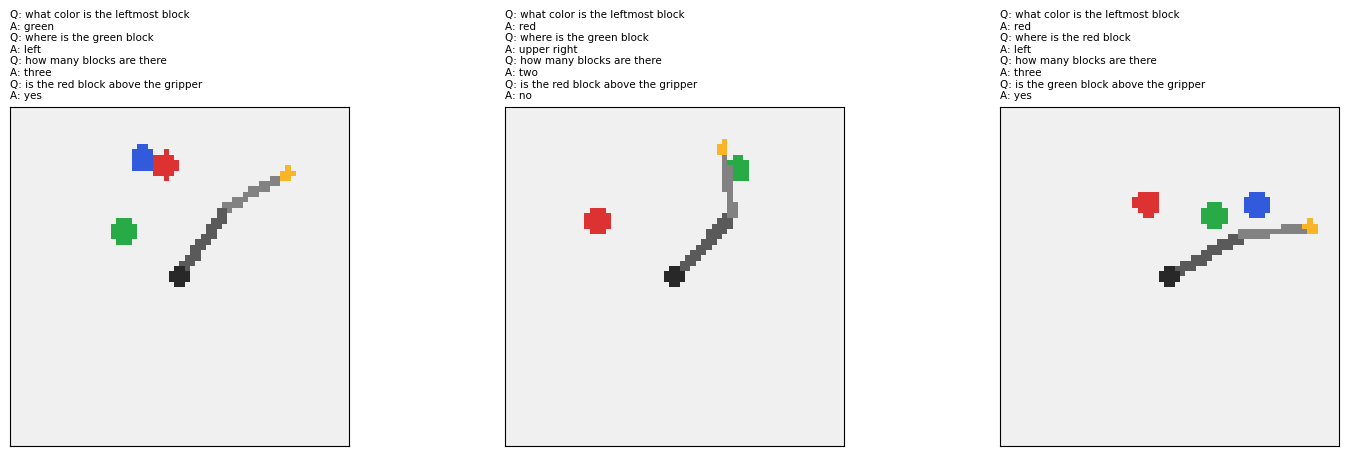

ブロックは 64x64 の画像上で直径5ピクセル程度しかない。
この細かさが、のちのエンコーダ設計で効いてくる。


In [3]:
# ============================================================
# 図1: 画像と問答の例
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, sd in zip(axes, [0, 1, 2]):
    img, qa, facts, _ = scene_with_questions(sd)
    ax.imshow(img)
    lines = [f"Q: {q}\nA: {a}" for q, a, _ in qa]
    ax.set_title("\n".join(lines), fontsize=7.5, loc="left")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.show()

print("ブロックは 64x64 の画像上で直径5ピクセル程度しかない。")
print("この細かさが、のちのエンコーダ設計で効いてくる。")

---

<a id="clip"></a>
## 3. CLIP では足りない

Notebook 44 の CLIP は、画像とテキストを**同じ空間に並べる**ように対比学習しました。
これで何ができて、何ができないのかを実測で確かめます。

ArmWorld の場面からキャプションを自動生成し、小さな CLIP を学習します。

In [4]:
# ============================================================
# 小さな CLIP（対比学習）
# ============================================================

def scene_caption(facts) -> str:
    return (f"{facts['count']} blocks the leftmost is {facts['left_color']} "
            f"and the {facts['first_color']} block is on the {facts['first_region']}")


clip_train = [(img, scene_caption(f)) for img, _, f, _ in
              (scene_with_questions(s) for s in range(N_TRAIN_SCENES))]
clip_val = [(img, scene_caption(f), f) for img, _, f, _ in
            (scene_with_questions(s) for s in VAL_SCENES)]

clip_words = set()
for _, c in clip_train:
    clip_words.update(c.split())
for _, c, _ in clip_val:
    clip_words.update(c.split())
for w in ["red", "blue", "green", "one", "two", "three", "upper", "left", "right"]:
    clip_words.add(w)
CLIP_VOCAB = ["<pad>"] + sorted(clip_words)
clip_stoi = {w: i for i, w in enumerate(CLIP_VOCAB)}
CLIP_MAXLEN = max(len(c.split()) for _, c in clip_train) + 2
D_CLIP = 64


def clip_tokens(text: str):
    ids = [clip_stoi[w] for w in text.split()][:CLIP_MAXLEN]
    return ids + [0] * (CLIP_MAXLEN - len(ids))


class ClipImageEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, 2, 1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.fc = nn.Linear(64, D_CLIP)

    def forward(self, x):
        return F.normalize(self.fc(self.cnn(x)), dim=-1)


class ClipTextEncoder(nn.Module):
    def __init__(self, n_vocab: int):
        super().__init__()
        self.emb = nn.Embedding(n_vocab, D_CLIP, padding_idx=0)
        self.pos = nn.Parameter(0.02 * torch.randn(1, CLIP_MAXLEN, D_CLIP))
        layer = nn.TransformerEncoderLayer(D_CLIP, 4, D_CLIP * 4, batch_first=True,
                                           norm_first=True, dropout=0.0)
        self.tr = nn.TransformerEncoder(layer, 2)
        self.fc = nn.Linear(D_CLIP, D_CLIP)

    def forward(self, t):
        h = self.tr(self.emb(t) + self.pos)
        mask = (t != 0).float()[..., None]
        pooled = (h * mask).sum(1) / mask.sum(1).clamp(min=1)
        return F.normalize(self.fc(pooled), dim=-1)


def train_clip(epochs: int = 30, batch: int = 64, lr: float = 1e-3, seed: int = SEED):
    torch.manual_seed(seed)
    img_enc, txt_enc = ClipImageEncoder(), ClipTextEncoder(len(CLIP_VOCAB))
    logit_scale = nn.Parameter(torch.tensor(np.log(1 / 0.07), dtype=torch.float32))
    opt = torch.optim.Adam(list(img_enc.parameters()) + list(txt_enc.parameters())
                           + [logit_scale], lr=lr)
    X = torch.as_tensor(np.array([i for i, _ in clip_train]).transpose(0, 3, 1, 2)
                        .astype(np.float32) / 255.0)
    T = torch.as_tensor([clip_tokens(c) for _, c in clip_train])
    t0 = time.time()
    for _ in range(epochs):
        order = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            b = order[i:i + batch]
            if len(b) < 8:
                continue
            z_i, z_t = img_enc(X[b]), txt_enc(T[b])
            logits = logit_scale.exp() * z_i @ z_t.T
            labels = torch.arange(len(b))
            loss = 0.5 * (F.cross_entropy(logits, labels)
                          + F.cross_entropy(logits.T, labels))
            opt.zero_grad(); loss.backward(); opt.step()
    return img_enc, txt_enc, float(loss.detach()), time.time() - t0


clip_img_enc, clip_txt_enc, clip_loss, clip_seconds = train_clip()
print(f"CLIP trained in {clip_seconds:.0f}s (final InfoNCE loss {clip_loss:.3f})")

/Users/ikmx/source/personal/machine-learning-playground/.venv/lib/python3.11/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


CLIP trained in 43s (final InfoNCE loss 1.962)


In [5]:
# ============================================================
# CLIP を「閉集合の分類器」として評価する
# ============================================================

CLOSED_SET = {
    "color":    (["red", "blue", "green"],
                 lambda f: f["left_color"], lambda a: f"the leftmost is {a}"),
    "count":    (["one", "two", "three"],
                 lambda f: f["count"], lambda a: f"{a} blocks"),
    "position": (["upper left", "upper right", "left", "right"],
                 lambda f: f["first_region"], lambda a: f"block is on the {a}"),
}

X_val = torch.as_tensor(np.array([i for i, _, _ in clip_val]).transpose(0, 3, 1, 2)
                        .astype(np.float32) / 255.0)
with torch.no_grad():
    z_img_val = clip_img_enc(X_val)

clip_scores = {}
for kind, (candidates, truth_of, template) in CLOSED_SET.items():
    with torch.no_grad():
        z_cand = clip_txt_enc(torch.as_tensor([clip_tokens(template(c)) for c in candidates]))
    pred = (z_img_val @ z_cand.T).argmax(1).numpy()
    gold = np.array([candidates.index(truth_of(f)) for _, _, f in clip_val])
    clip_scores[kind] = {"acc": float((pred == gold).mean()), "chance": 1 / len(candidates)}

print(f"{'kind':10s} {'CLIP acc':>9s} {'chance':>8s}")
for k, v in clip_scores.items():
    print(f"{k:10s} {v['acc']:9.3f} {v['chance']:8.2f}")
print()
print("count と color は偶然を上回る。一方 position は偶然のままで、")
print("『どの色がどこにあるか』という属性と位置の結びつけは学べていない。")
print("そして構造的な限界がある: CLIP は『候補を並べて点数をつける』ことしかできない。")
print("候補に無い答えは絶対に出せず、yes/no のような問い方も素直には扱えない。")

kind        CLIP acc   chance
color          0.573     0.33
count          0.783     0.33
position       0.257     0.25

count と color は偶然を上回る。一方 position は偶然のままで、
『どの色がどこにあるか』という属性と位置の結びつけは学べていない。
そして構造的な限界がある: CLIP は『候補を並べて点数をつける』ことしかできない。
候補に無い答えは絶対に出せず、yes/no のような問い方も素直には扱えない。


### 読み取れること

`count`（0.78）と `color`（0.57）は偶然を上回りました。画像の大域的な性質
（いくつあるか、どんな色が写っているか）は対比学習でも掴めます。

一方 `position` は偶然のままでした。これは「**どの色のブロックがどこにあるか**」という
属性と位置の**結びつけ**を要求する問いです。CLIP の画像側は最後に
`AdaptiveAvgPool2d(1)` で空間を潰して1ベクトルにしているので、
この情報は構造的に失われています。

### CLIP の2つの限界

1. **閉集合しか扱えない**。答えの候補を人間が列挙し、テンプレートに埋めて
   スコアを比べる必要があります。「この画像について説明して」には答えられません。
2. **問いを条件にできない**。CLIP が計算するのは画像とテキストの類似度だけで、
   「どの問いに答えているか」という構造がありません。
   `color` と `position` を同時に正しく扱うには、問いごとに別のテンプレート集合を
   人間が用意することになります。

必要なのは、**画像を条件として言語を生成する**モデルです。

---

<a id="llava"></a>
## 4. LLaVA 型の構成

LLaVA のアイデアはきわめて単純です。

```
画像 --[ビジョンエンコーダ]--> 特徴マップ --[projector]--> 画像トークン列
                                                              |
                                      [画像トークン] + [質問トークン] --> LM --> 答え
```

**画像を「言語モデルにとってのトークン列」に変換してしまう**。
あとは普通の言語モデルの次トークン予測です。

| 部品 | 本章の実装 | 実物の LLaVA |
|---|---|---|
| ビジョンエンコーダ | 小さな CNN（3層, stride 2） | CLIP ViT-L/14（凍結） |
| 画像トークン数 | 8x8 = 64 | 256（ViT のパッチ数） |
| projector | 線形1層 | 線形または2層MLP |
| 言語モデル | 2層 Transformer（スクラッチ） | Vicuna / Llama（事前学習済み） |
| 学習データ | 6,000 問答 | 60万〜 |

**本章のミニチュアと実物の最大の違いは「事前学習済みかどうか」です。**
そこが結果を分けることを、これから実測します。

### 損失は答えの位置だけにかける

質問文まで予測させる必要はありません（入力として与えられているので）。
答えのトークンと `<eos>` の位置だけを教師信号にします。
これは Notebook 167 の指示チューニングと同じ考え方です。

In [6]:
# ============================================================
# トークナイザと VLM 本体
# ============================================================

words = set()
for text in Q + A + Q_V + A_V:
    words.update(text.split())
VOCAB = ["<pad>", "<bos>", "<eos>"] + sorted(words)
stoi = {w: i for i, w in enumerate(VOCAB)}
D_MODEL = 128
N_IMG_TOKENS = 64          # 8x8 の特徴マップを 64 個の画像トークンにする


def encode(text: str):
    return [stoi[w] for w in text.split()]


class VisionEncoder(nn.Module):
    '''64x64 -> 8x8 の特徴マップ。

    stride 2 を3回（4回ではなく）にしているのは、ブロックが直径5ピクセル程度しか
    ないため。4回downsampleすると 4x4 になり、位置の問いに答えられなくなる。
    '''

    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, 2, 1), nn.ReLU())

    def forward(self, x):
        return self.cnn(x)                      # (B, 64, 8, 8)


class VLM(nn.Module):
    '''画像トークンを prefix として LM に流し込む LLaVA 型のミニチュア。'''

    def __init__(self, n_vocab: int, encoder: nn.Module, d: int = D_MODEL,
                 n_layer: int = 2, n_head: int = 4):
        super().__init__()
        self.encoder = encoder
        self.projector = nn.Linear(64, d)       # ここが projector
        self.emb = nn.Embedding(n_vocab, d)
        self.pos = nn.Parameter(0.02 * torch.randn(1, N_IMG_TOKENS + 24, d))
        layer = nn.TransformerEncoderLayer(d, n_head, d * 4, batch_first=True,
                                           norm_first=True, dropout=0.0)
        self.lm = nn.TransformerEncoder(layer, n_layer)
        self.head = nn.Linear(d, n_vocab)

    def image_tokens(self, img):
        feat = self.encoder(img)                        # (B, 64, 8, 8)
        feat = feat.flatten(2).transpose(1, 2)          # (B, 64, 64)
        return self.projector(feat)                     # (B, 64, d)

    def forward(self, img, tok):
        it = self.image_tokens(img)
        x = torch.cat([it, self.emb(tok)], dim=1)
        x = x + self.pos[:, :x.shape[1]]
        L = x.shape[1]
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool), 1)
        h = self.lm(x, mask=causal)
        # h[n_img-1+j] は「画像 + text[0..j-1]」を見た状態 -> text[j] を予測する。
        # 長さを L_text+1 にしておくと、末尾が「次の1トークン」の予測になる（生成で使う）。
        return self.head(h[:, it.shape[1] - 1:])


def make_batch(images, questions, answers, idx):
    seqs = [[stoi["<bos>"]] + encode(questions[i]) + encode(answers[i]) + [stoi["<eos>"]]
            for i in idx]
    L = max(len(s) for s in seqs)
    tok = np.full((len(idx), L), stoi["<pad>"], dtype=np.int64)
    tgt = np.full((len(idx), L), -100, dtype=np.int64)
    for b, i in enumerate(idx):
        s = seqs[b]
        tok[b, :len(s)] = s
        answer_len = len(encode(answers[i])) + 1        # 答え + <eos>
        start = len(s) - answer_len
        tgt[b, start:len(s)] = s[start:]                # 答えの位置だけ学習する
    x = torch.as_tensor(images[idx].transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
    return x, torch.as_tensor(tok), torch.as_tensor(tgt)


def train_vlm(net, epochs: int = 20, batch: int = 64, lr: float = 1e-3):
    params = [p for p in net.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr)
    history = []
    t0 = time.time()
    for _ in range(epochs):
        order = np.random.permutation(len(Q))
        total, n = 0.0, 0
        for i in range(0, len(Q), batch):
            idx = order[i:i + batch]
            x, tok, tgt = make_batch(IMG, Q, A, idx)
            logits = net(x, tok)
            L = tgt.shape[1]
            loss = F.cross_entropy(logits[:, :L].reshape(-1, logits.shape[-1]),
                                   tgt.reshape(-1), ignore_index=-100)
            opt.zero_grad(); loss.backward(); opt.step()
            total += float(loss.detach()) * len(idx); n += len(idx)
        history.append(total / n)
    return np.array(history), time.time() - t0


@torch.no_grad()
def vlm_accuracy(net, images=None, questions=None, answers=None, kinds=None,
                 return_predictions: bool = False):
    images = IMG_V if images is None else images
    questions = Q_V if questions is None else questions
    answers = A_V if answers is None else answers
    kinds = KIND_V if kinds is None else kinds
    correct, total, preds = {}, {}, []
    for i in range(len(questions)):
        x = torch.as_tensor(images[i:i + 1].transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
        seq = [stoi["<bos>"]] + encode(questions[i])
        out = []
        for _ in range(3):
            logits = net(x, torch.as_tensor([seq]))
            nxt = int(logits[0, -1].argmax())
            if nxt == stoi["<eos>"]:
                break
            out.append(VOCAB[nxt]); seq.append(nxt)
        pred = " ".join(out)
        preds.append(pred)
        k = kinds[i]
        total[k] = total.get(k, 0) + 1
        correct[k] = correct.get(k, 0) + int(pred == answers[i])
    per_kind = {k: correct[k] / total[k] for k in total}
    overall = sum(correct.values()) / sum(total.values())
    return (per_kind, overall, preds) if return_predictions else (per_kind, overall)


print("vocabulary:", len(VOCAB), VOCAB[:8], "...")
demo = VLM(len(VOCAB), VisionEncoder())
print("VLM parameters:", f"{sum(p.numel() for p in demo.parameters()):,}")
x_demo, tok_demo, tgt_demo = make_batch(IMG, Q, A, np.arange(4))
print("forward:", tuple(x_demo.shape), tuple(tok_demo.shape), "->",
      tuple(demo(x_demo, tok_demo).shape))

vocabulary: 27 ['<pad>', '<bos>', '<eos>', 'above', 'are', 'block', 'blocks', 'blue'] ...
VLM parameters: 479,387
forward: (4, 3, 64, 64) (4, 10) -> (4, 11, 27)


/Users/ikmx/source/personal/machine-learning-playground/.venv/lib/python3.11/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


---

<a id="scratch"></a>
## 5. スクラッチ学習は当て推量に留まる

まず**全部をスクラッチから**学習します。ビジョンエンコーダも projector も LM も同時に。
これが素直な実装です。

In [7]:
# ============================================================
# スクラッチ学習（エンコーダも LM も同時に学習）
# ============================================================

torch.manual_seed(SEED)
np.random.seed(SEED)
vlm_scratch = VLM(len(VOCAB), VisionEncoder())
hist_scratch, sec_scratch = train_vlm(vlm_scratch, epochs=20)
per_scratch, overall_scratch = vlm_accuracy(vlm_scratch)
print(f"scratch VLM: trained {sec_scratch:.0f}s, final loss {hist_scratch[-1]:.3f}")
print(f"  overall accuracy: {overall_scratch:.3f}")
for k in sorted(per_scratch):
    print(f"    {k:10s} {per_scratch[k]:.3f}   (majority baseline {baseline[k]:.3f})")
print()
print("多数クラスベースラインとほとんど変わらない。画像を使えていない。")

scratch VLM: trained 140s, final loss 0.450
  overall accuracy: 0.453
    color      0.333   (majority baseline 0.377)
    count      0.507   (majority baseline 0.507)
    position   0.233   (majority baseline 0.273)
    yesno      0.740   (majority baseline 0.740)

多数クラスベースラインとほとんど変わらない。画像を使えていない。


### これはモデルの大きさの問題なのか

まず「画像そのものが読めないのか」を切り分けます。
同じ CNN を**分類器として直接**学習してみます。

In [8]:
# ============================================================
# 切り分け: CNN 単体なら画像を読めるのか
# ============================================================

COLOR_INDEX = {"red": 0, "blue": 1, "green": 2}


def build_classification_data(scene_ids):
    X, y_color, y_count = [], [], []
    for sd in scene_ids:
        img, _, facts, env = scene_with_questions(sd)
        X.append(img)
        y_color.append(COLOR_INDEX[facts["left_color"]])
        y_count.append(len(env.block_pos) - 2)
    return (np.array(X), np.array(y_color), np.array(y_count))


Xc, yc, yn = build_classification_data(range(N_TRAIN_SCENES))
Xc_v, yc_v, yn_v = build_classification_data(VAL_SCENES)


def probe_cnn(y_train, y_val, n_classes: int, epochs: int = 20, seed: int = SEED):
    torch.manual_seed(seed)
    net = nn.Sequential(VisionEncoder(), nn.Flatten(),
                        nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Linear(128, n_classes))
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    xt = torch.as_tensor(Xc.transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
    yt = torch.as_tensor(y_train)
    xv = torch.as_tensor(Xc_v.transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
    yv = torch.as_tensor(y_val)
    for _ in range(epochs):
        order = torch.randperm(len(xt))
        for i in range(0, len(xt), 64):
            b = order[i:i + 64]
            loss = F.cross_entropy(net(xt[b]), yt[b])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return float((net(xv).argmax(-1) == yv).float().mean())


acc_color_probe = probe_cnn(yc, yc_v, 3)
acc_count_probe = probe_cnn(yn, yn_v, 2)
print(f"CNN alone -> leftmost color : {acc_color_probe:.3f}  (chance 0.33)")
print(f"CNN alone -> block count    : {acc_count_probe:.3f}  (chance 0.50)")
print()
print("画像は読める。つまり問題はエンコーダの能力ではなく、")
print("『画像トークンを LM に使わせること』の学習の難しさにある。")

CNN alone -> leftmost color : 0.880  (chance 0.33)
CNN alone -> block count    : 0.937  (chance 0.50)

画像は読める。つまり問題はエンコーダの能力ではなく、
『画像トークンを LM に使わせること』の学習の難しさにある。


### 何が起きているのか

スクラッチ学習では、モデルは同時に3つのことを学ばなければなりません。

1. 画像から意味のある特徴を取り出す（視覚）
2. 単語の意味と文の構造を学ぶ（言語）
3. 64個の画像トークンのうち**どれを見るべきか**を学ぶ（接続）

このうち 3 は 1 と 2 ができていないと学べません。
視覚特徴がまだ無意味で、言語も未習得な段階では、
「画像トークンに注意を向ける」ことに報酬がありません。
**最も簡単な解は「答えの事前分布を覚えること」**で、そこに落ち着きます。

実測の損失もそれを裏づけます。損失はすぐ下がり止まり、
多数クラスベースライン相当の精度で止まります。

> **これが LLaVA が凍結した事前学習済みエンコーダと事前学習済み LLM を使う理由です。**
> 1 と 2 を**他人（大規模事前学習）に任せて**、3 だけを学習する。
> projector は「既に有能な2つの系を繋ぐ」仕事に専念できます。

---

<a id="frozen"></a>
## 6. 凍結した事前学習エンコーダに替える

実物の LLaVA に倣って、ビジョンエンコーダを**先に別タスクで事前学習して凍結**します。

本章では CLIP の代わりに、補助タスク（一番左のブロックの色・ブロックの個数）で
エンコーダを教師あり事前学習します。小さな環境では対比学習より安定し、
「エンコーダが既に有能」という条件を再現するのが目的なので十分です。

> 実物では CLIP の画像側をそのまま凍結して使います。
> 本章の `clip_img_enc`（第3節）を使ってもよいのですが、
> AdaptiveAvgPool で空間情報を潰してしまっているため位置の問いに弱く、
> ここでは空間を保ったエンコーダを別に用意します。
> **「どの事前学習タスクを選ぶかが下流で効く」**ことの実例でもあります。

In [9]:
# ============================================================
# エンコーダの事前学習と凍結
# ============================================================

def pretrain_vision_encoder(epochs: int = 15, seed: int = SEED):
    '''補助タスク（色3クラス + 個数2クラス）でエンコーダを学習し、凍結して返す。'''
    torch.manual_seed(seed)
    encoder = VisionEncoder()
    head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(),
                         nn.Linear(128, 5))      # 3(色) + 2(個数)
    opt = torch.optim.Adam(list(encoder.parameters()) + list(head.parameters()), lr=1e-3)
    xt = torch.as_tensor(Xc.transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
    y_color = torch.as_tensor(yc); y_count = torch.as_tensor(yn)
    t0 = time.time()
    for _ in range(epochs):
        order = torch.randperm(len(xt))
        for i in range(0, len(xt), 64):
            b = order[i:i + 64]
            out = head(encoder(xt[b]))
            loss = (F.cross_entropy(out[:, :3], y_color[b])
                    + F.cross_entropy(out[:, 3:], y_count[b]))
            opt.zero_grad(); loss.backward(); opt.step()
    for p in encoder.parameters():
        p.requires_grad = False                  # 凍結
    return encoder, time.time() - t0


frozen_encoder, pretrain_seconds = pretrain_vision_encoder()
print(f"vision encoder pretrained and frozen in {pretrain_seconds:.0f}s")

torch.manual_seed(SEED)
np.random.seed(SEED)
vlm_frozen = VLM(len(VOCAB), frozen_encoder)
trainable = sum(p.numel() for p in vlm_frozen.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in vlm_frozen.parameters())
print(f"trainable parameters: {trainable:,} / {total_params:,} "
      f"({trainable / total_params:.0%}) — 残りは凍結したエンコーダ")

hist_frozen, sec_frozen = train_vlm(vlm_frozen, epochs=20)
per_frozen, overall_frozen = vlm_accuracy(vlm_frozen)
print(f"frozen-encoder VLM: trained {sec_frozen:.0f}s, final loss {hist_frozen[-1]:.3f}")
print(f"  overall accuracy: {overall_frozen:.3f}")
for k in sorted(per_frozen):
    print(f"    {k:10s} {per_frozen[k]:.3f}   (scratch {per_scratch[k]:.3f},"
          f" majority {baseline[k]:.3f})")

vision encoder pretrained and frozen in 19s
trainable parameters: 423,067 / 479,387 (88%) — 残りは凍結したエンコーダ


frozen-encoder VLM: trained 97s, final loss 0.059
  overall accuracy: 0.908
    color      0.903   (scratch 0.333, majority 0.377)
    count      0.890   (scratch 0.507, majority 0.507)
    position   0.900   (scratch 0.233, majority 0.273)
    yesno      0.940   (scratch 0.740, majority 0.740)


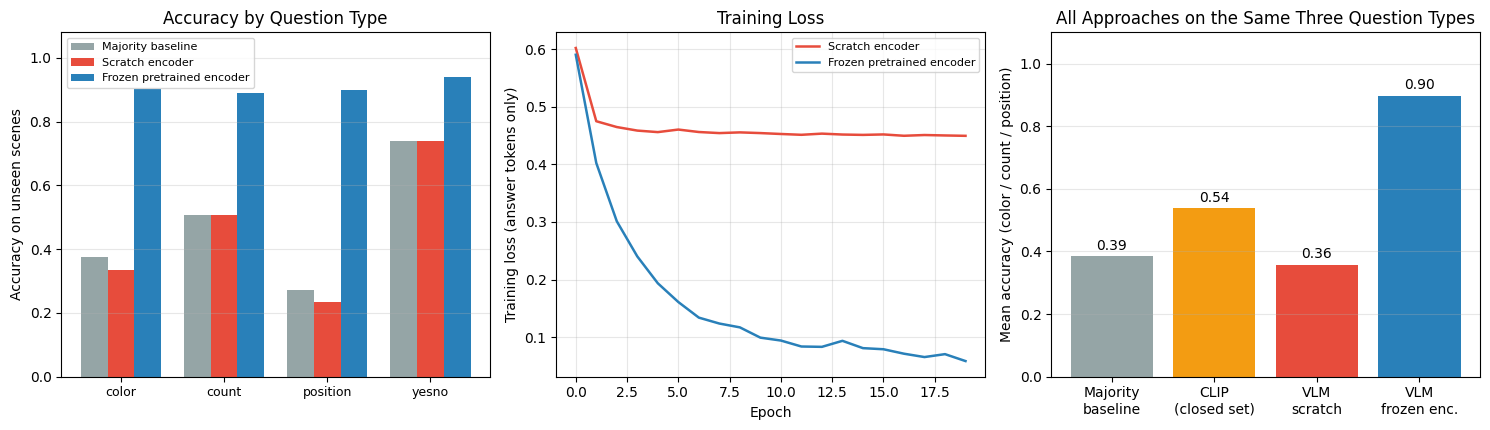

approach                       color   count  position
majority baseline              0.377   0.507     0.273
CLIP (closed set scoring)      0.573   0.783     0.257
VLM scratch encoder            0.333   0.507     0.233
VLM frozen pretrained enc.     0.903   0.890     0.900


In [10]:
# ============================================================
# 図2: スクラッチ vs 凍結事前学習エンコーダ
# ============================================================

kinds_sorted = sorted(per_frozen)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
x = np.arange(len(kinds_sorted))
w = 0.26
ax.bar(x - w, [baseline[k] for k in kinds_sorted], w, color="#95A5A6", label="Majority baseline")
ax.bar(x, [per_scratch[k] for k in kinds_sorted], w, color="#E74C3C", label="Scratch encoder")
ax.bar(x + w, [per_frozen[k] for k in kinds_sorted], w, color="#2980B9",
       label="Frozen pretrained encoder")
ax.set_xticks(x); ax.set_xticklabels(kinds_sorted, fontsize=9)
ax.set_ylabel("Accuracy on unseen scenes")
ax.set_ylim(0, 1.08)
ax.set_title("Accuracy by Question Type")
ax.legend(fontsize=8)
ax.grid(axis="x")

ax = axes[1]
ax.plot(hist_scratch, color="#E74C3C", lw=1.8, label="Scratch encoder")
ax.plot(hist_frozen, color="#2980B9", lw=1.8, label="Frozen pretrained encoder")
ax.set_xlabel("Epoch"); ax.set_ylabel("Training loss (answer tokens only)")
ax.set_title("Training Loss")
ax.legend(fontsize=8)

ax = axes[2]
names = ["Majority\nbaseline", "CLIP\n(closed set)", "VLM\nscratch", "VLM\nfrozen enc."]
clip_mean = float(np.mean([v["acc"] for v in clip_scores.values()]))
base_mean = float(np.mean([baseline[k] for k in ["color", "count", "position"]]))
vals = [base_mean, clip_mean,
        float(np.mean([per_scratch[k] for k in ["color", "count", "position"]])),
        float(np.mean([per_frozen[k] for k in ["color", "count", "position"]]))]
bars = ax.bar(names, vals, color=["#95A5A6", "#F39C12", "#E74C3C", "#2980B9"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=10)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Mean accuracy (color / count / position)")
ax.set_title("All Approaches on the Same Three Question Types")
ax.grid(axis="x")

plt.tight_layout()
plt.show()

print(f"{'approach':28s} {'color':>7s} {'count':>7s} {'position':>9s}")
print(f"{'majority baseline':28s} {baseline['color']:7.3f} {baseline['count']:7.3f} "
      f"{baseline['position']:9.3f}")
print(f"{'CLIP (closed set scoring)':28s} {clip_scores['color']['acc']:7.3f} "
      f"{clip_scores['count']['acc']:7.3f} {clip_scores['position']['acc']:9.3f}")
print(f"{'VLM scratch encoder':28s} {per_scratch['color']:7.3f} {per_scratch['count']:7.3f} "
      f"{per_scratch['position']:9.3f}")
print(f"{'VLM frozen pretrained enc.':28s} {per_frozen['color']:7.3f} {per_frozen['count']:7.3f} "
      f"{per_frozen['position']:9.3f}")

### これが LLaVA の2段階学習の意味

LLaVA の学習は2段階です。

| 段階 | 学習するもの | 凍結するもの | 目的 |
|---|---|---|---|
| Stage 1 | projector だけ | ビジョンエンコーダ、LLM | 2つの空間を**整合**させる |
| Stage 2 | projector + LLM | ビジョンエンコーダ | **指示に従う**ことを学ぶ |

本章で測った「スクラッチでは当て推量、凍結事前学習エンコーダなら跳ねる」は、
この設計が**必要**であることの最小の実証です。

**人間の学習に例えるなら**: 目も言葉も未発達な状態で
「画像を見て質問に答える」練習をしても何も学べません。
先に見ることと話すことを別々に習得して、それから両者を繋ぐ練習をします。

---

<a id="saliency"></a>
## 7. 画像のどこを見て答えたか

VLM が本当に画像を見ているなら、答えに効いた**画像の領域**があるはずです。
入力画像に関する勾配（saliency）で可視化します。

$$\text{saliency}(x) = \left\lvert \frac{\partial\, \log p(\text{answer})}{\partial x} \right\rvert$$

アテンション重みを取り出す方法もありますが、`nn.TransformerEncoder` は
重みを外に出さないので、ここでは入力勾配を使います。

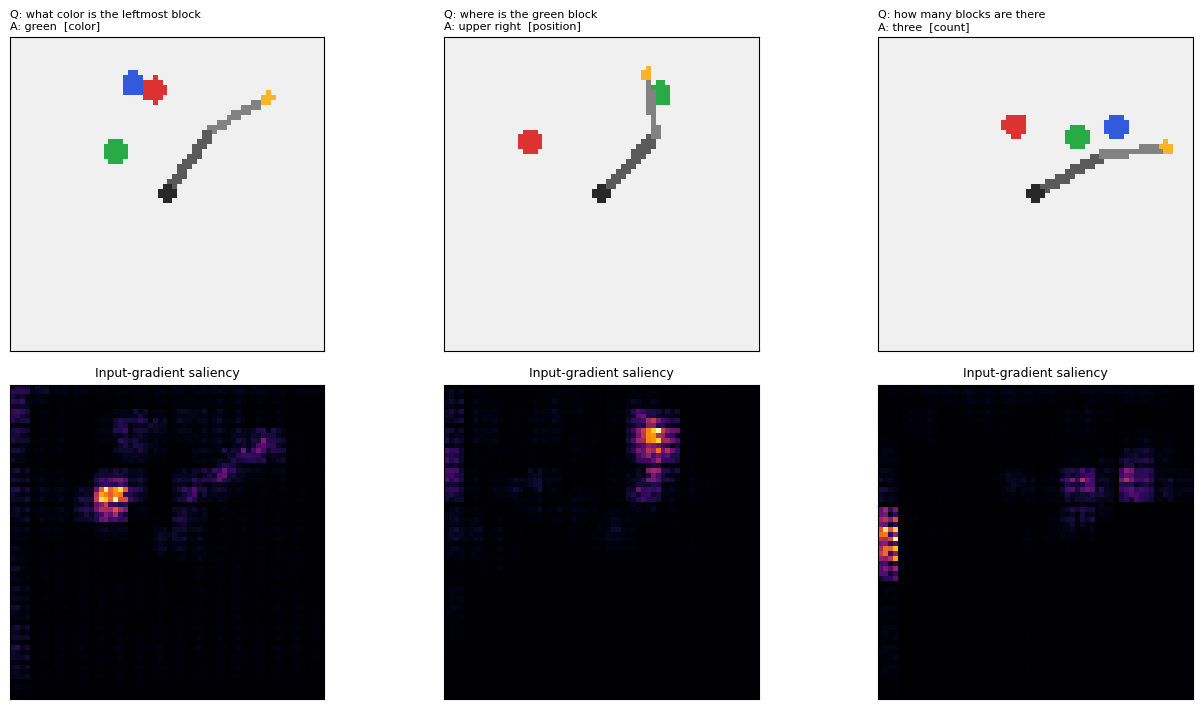

明るい領域が答えに効いた画素。ブロックやアームの周辺に集まっていれば、
モデルが『見るべきところ』を見ていることの傍証になる。
（saliency は傍証であって証明ではない。アテンションも同様。）


In [11]:
# ============================================================
# 図3: 入力勾配による saliency
# ============================================================

def saliency_map(net, image, question, answer):
    '''答えのトークンの対数確率を画像で微分して、効いた領域を見る。'''
    x = torch.as_tensor(image[None].transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
    x.requires_grad_(True)
    seq = [stoi["<bos>"]] + encode(question)
    answer_ids = encode(answer)
    logits = net(x, torch.as_tensor([seq + answer_ids]))
    log_probs = torch.log_softmax(logits[0], dim=-1)
    score = 0.0
    for j, tid in enumerate(answer_ids):
        score = score + log_probs[len(seq) - 1 + j, tid]
    score.backward()
    return x.grad.abs().sum(1)[0].numpy()


examples = [(0, 0), (1, 1), (2, 2)]     # (scene id, question index)
fig, axes = plt.subplots(2, len(examples), figsize=(4.6 * len(examples), 7.2))
for col, (sd, qi) in enumerate(examples):
    img, qa, _, _ = scene_with_questions(sd)
    q, a, kind = qa[qi]
    sal = saliency_map(vlm_frozen, img, q, a)
    axes[0, col].imshow(img)
    axes[0, col].set_title(f"Q: {q}\nA: {a}  [{kind}]", fontsize=8, loc="left")
    axes[0, col].set_xticks([]); axes[0, col].set_yticks([]); axes[0, col].grid(False)
    axes[1, col].imshow(sal, cmap="inferno")
    axes[1, col].set_title("Input-gradient saliency", fontsize=9)
    axes[1, col].set_xticks([]); axes[1, col].set_yticks([]); axes[1, col].grid(False)
plt.tight_layout()
plt.show()

print("明るい領域が答えに効いた画素。ブロックやアームの周辺に集まっていれば、")
print("モデルが『見るべきところ』を見ていることの傍証になる。")
print("（saliency は傍証であって証明ではない。アテンションも同様。）")

---

<a id="hallucination"></a>
## 8. 幻覚の観察

VLM は**画像に無いものについても自信を持って答えます**。
存在しない色のブロックについて尋ねてみます。

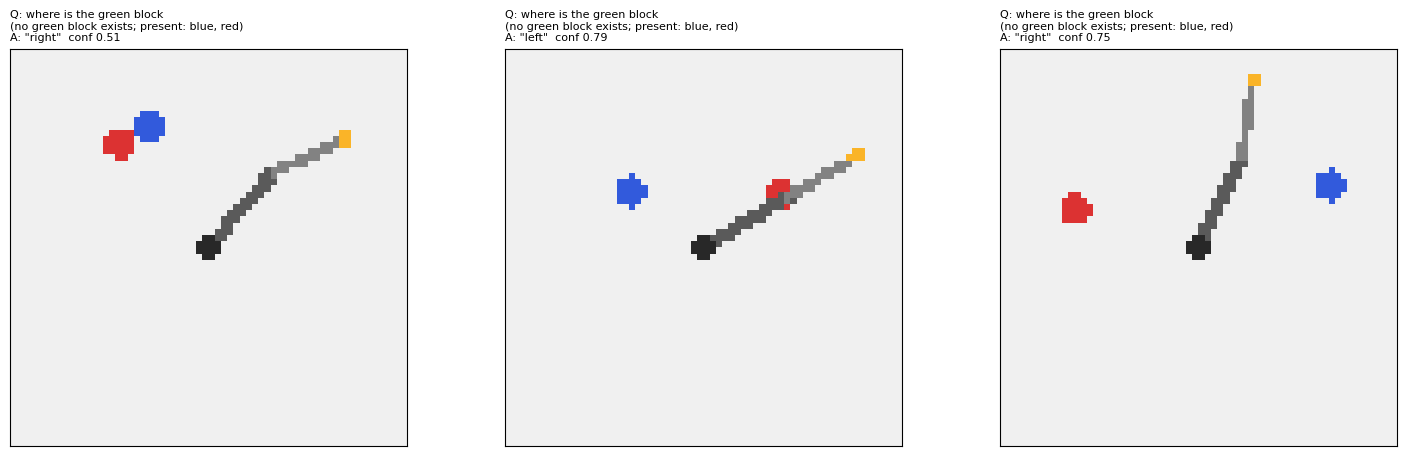

存在しない物体についての問い 19 件:
  平均確信度 0.76
  『無い』と答えた割合: 0.00

学習データに『存在しない物体についての問い』が1件も入っていないので、
モデルは必ず何らかの位置を答える。これは能力の欠陥ではなく、
**データ設計の欠陥**である。拒否の仕方を見せていないものは学べない。


In [12]:
# ============================================================
# 図4: 画像に無い物体について尋ねる
# ============================================================

hallucination_rows = []
for sd in range(5300, 5340):
    img, _, facts, env = scene_with_questions(sd)
    present = set(env.block_colors)
    absent = [c for c in ["red", "blue", "green"] if c not in present]
    if not absent:
        continue
    missing = absent[0]
    q = f"where is the {missing} block"
    x = torch.as_tensor(img[None].transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
    seq = [stoi["<bos>"]] + encode(q)
    out = []
    with torch.no_grad():
        for _ in range(3):
            logits = vlm_frozen(x, torch.as_tensor([seq]))
            probs = torch.softmax(logits[0, -1], dim=-1)
            nxt = int(probs.argmax())
            if nxt == stoi["<eos>"]:
                break
            out.append((VOCAB[nxt], float(probs[nxt]))); seq.append(nxt)
    hallucination_rows.append({"seed": sd, "missing": missing,
                               "answer": " ".join(w for w, _ in out),
                               "confidence": float(np.mean([p for _, p in out])) if out else 0.0,
                               "image": img, "present": sorted(present)})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, row in zip(axes, hallucination_rows[:3]):
    ax.imshow(row["image"])
    ax.set_title(f'Q: where is the {row["missing"]} block\n'
                 f'(no {row["missing"]} block exists; present: {", ".join(row["present"])})\n'
                 f'A: "{row["answer"]}"  conf {row["confidence"]:.2f}', fontsize=8, loc="left")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.show()

print(f"存在しない物体についての問い {len(hallucination_rows)} 件:")
print(f"  平均確信度 {np.mean([r['confidence'] for r in hallucination_rows]):.2f}")
print(f"  『無い』と答えた割合: "
      f"{np.mean([r['answer'] in ('', 'no') for r in hallucination_rows]):.2f}")
print()
print("学習データに『存在しない物体についての問い』が1件も入っていないので、")
print("モデルは必ず何らかの位置を答える。これは能力の欠陥ではなく、")
print("**データ設計の欠陥**である。拒否の仕方を見せていないものは学べない。")

---

<a id="summary"></a>
## 9. まとめとチートシート

### この章で学んだこと

- **CLIP は閉集合の分類器として使えるが、答えを生成できない**。
  候補を人間が列挙してテンプレートに埋める必要がある。実測では `count` と `color` は
  偶然を上回ったが、`position`（属性と位置の結びつけ）は偶然のままだった。
- **LLaVA 型の構成は単純**: 画像 → エンコーダ → projector → 画像トークン列 → LM の prefix。
  あとは普通の次トークン予測。損失は答えの位置だけにかける（167 の指示チューニングと同じ）。
- **スクラッチ学習では当て推量に留まる**。CNN 単体なら画像が読めることを確認したので、
  原因はエンコーダの能力ではなく「視覚・言語・接続を同時に学ぶのが無理」ということ。
- **凍結した事前学習エンコーダに替えると性能が跳ねる**。
  これが LLaVA の2段階学習（Stage 1: projector だけ / Stage 2: LLM も解凍）の理由。
- **ダウンサンプリングの深さが位置の問いを左右する**。ブロックが直径5ピクセルしかない
  ため、stride 2 を4回かけて 4x4 にすると位置が答えられない。3回で 8x8 にした。
- **幻覚はデータ設計の問題**。「存在しないものについての問い」を学習データに
  入れていないので、モデルは必ず何かを答える。

### チートシート

```python
# 画像トークン化（これが VLM の全体像）
feat   = vision_encoder(image)            # (B, C, H', W')  例: (B, 64, 8, 8)
tokens = feat.flatten(2).transpose(1, 2)  # (B, H'*W', C)   例: (B, 64, 64)
tokens = projector(tokens)                # (B, 64, d_model) <- LM の埋め込み空間へ

# LM への prefix 注入
x = torch.cat([tokens, text_embedding(tok)], dim=1)
h = lm(x, mask=causal_mask(x.shape[1]))
logits = head(h[:, n_image_tokens - 1:])  # 画像末尾以降が「次トークン」の予測

# 損失は答えの位置だけ
tgt = full((B, L), -100)                  # -100 = ignore_index
tgt[:, answer_start:answer_end] = answer_ids
loss = F.cross_entropy(logits.reshape(-1, V), tgt.reshape(-1), ignore_index=-100)

# 凍結
for p in vision_encoder.parameters():
    p.requires_grad = False
opt = Adam([p for p in model.parameters() if p.requires_grad], lr=...)
```

### よくある間違い

| 間違い | 何が起きるか | 対処 |
|---|---|---|
| 全部スクラッチで学習する | 答えの事前分布を覚えて終わる | エンコーダ（と LM）は事前学習済みを凍結して使う |
| 精度をベースラインと比べない | 「学習できている」と誤認する | 多数クラスベースラインを必ず併記する |
| 画像を読めないのをモデル容量のせいにする | 間違った方向に大きくする | **CNN 単体で切り分ける**（本章の第5節） |
| ダウンサンプリングを深くしすぎる | 位置の問いに答えられない | 対象の画素サイズから逆算して決める |
| 生成の添字を1つずらす | 損失は下がるのに精度が 0 になる | 「次トークン」の予測位置を単体で確認する |
| 拒否の例をデータに入れない | 存在しない物体にも自信満々に答える | 「無い」と答える例を混ぜる |

> **5行目は実際に踏んだ間違いです**。損失は下がるのに精度がちょうど 0 になったときは、
> 学習ではなくデコード側の添字を疑ってください。

### 次のノートブックへ

これで V（画像トークン）と L（言語モデル）が繋がりました。
残っているのは **A（行動）** を接続することです。

Notebook 174 では、本章の VLM に 171 の行動トークンヘッドと 172 の拡散ヘッドを付け、
**言語指示で条件づけた方針**を作ります。
さらに 143/145 の世界モデルで候補を想像して選び直す、という合流をやります。

---

<a id="quiz"></a>
## 10. 自己評価クイズ

### Q1: CLIP と VLM の構造的な違い

**問題**: CLIP で VQA を解こうとすると何が必要になりますか。
VLM ならなぜそれが不要なのですか。

<details>
<summary>答えを見る</summary>

CLIP は画像とテキストの**類似度**しか計算しません。VQA に使うには
①答えの候補をすべて列挙する ②各候補を自然文テンプレートに埋める
③類似度を比べて最大のものを選ぶ、という手続きが必要です。
候補に無い答えは原理的に出せません。

VLM は画像を条件とした**言語の生成モデル** $p(\text{text} \mid \text{image})$ なので、
答えを1トークンずつ作れます。候補の列挙が要りません。
また問いもテキストとして条件に入るので、問いの種類ごとにテンプレートを
用意する必要がありません。
</details>

---

### Q2: スクラッチ学習が失敗する理由

**問題**: 本章のスクラッチ VLM は多数クラスベースライン程度に留まりました。
一方で同じ CNN を分類器として学習すると画像が読めました。
この2つの事実から、何が学習できていないと言えますか。

<details>
<summary>答えを見る</summary>

**画像トークンへの接続（どの画像トークンを見るべきか）**が学習できていません。

CNN 単体で読めるので「画像から特徴を取る能力」は足りています。
しかし VLM の設定では、その特徴が LM にとって意味のある形で使われるためには
①視覚特徴が既に有意味 ②言語側が既に文を扱える という前提が要ります。
どちらも未習得な状態では、画像トークンに注意を向けることに利得がなく、
勾配は「答えの事前分布を覚える」という最も簡単な解に向かいます。

だから LLaVA は ①②を大規模事前学習に任せ、③だけを projector で学習します。
</details>

---

### Q3: ダウンサンプリングの深さ

**問題**: 本章はビジョンエンコーダの stride 2 を3回（8x8 の特徴マップ）にしました。
4回（4x4）にすると何の問いが壊れますか。理由を画素数から説明してください。

<details>
<summary>答えを見る</summary>

**位置の問い**（`where is the {color} block`）が壊れます。

ArmWorld の描画は 4.0 ワールド単位を 64 画素に写すので 16 px/unit、
ブロック半径 0.16 unit は約2.6 px、直径で約5 px です。
stride 2 を4回かけると 1/16 に縮むので、ブロック全体が1セル未満になります。
色の情報は残っても、4つの領域を区別できるだけの空間解像度が失われます。

一般には「対象が特徴マップ上で最低何セルを占めるべきか」から逆算します。
対象が小さいときは downsample を浅くするか、入力解像度を上げます。
</details>

---

### Q4: 損失を答えの位置だけにかける理由

**問題**: 本章では質問文のトークンには損失をかけず、答えと `<eos>` だけに
かけました。質問文も予測させるとどうなりますか。

<details>
<summary>答えを見る</summary>

質問文は入力として与えられているので、予測できても何の役にも立ちません。
それでも損失に含めると、

- 勾配の大部分が「質問文の言語モデリング」に使われ、答えを当てる学習が薄まる
- 質問文は数種類のテンプレートしかないので、すぐ覚えてしまい損失が見かけ上小さくなる
  （評価指標として役に立たなくなる）

という害があります。Notebook 167 の指示チューニングでも、
損失は応答部分にのみかけるのが標準です。

一方、事前学習（164 の GPT）では全トークンに損失をかけます。
目的が「言語そのものを学ぶ」ことなので、そこは逆になります。
</details>

---

### Q5: 幻覚の責任

**問題**: 本章の VLM は存在しないブロックについても自信を持って位置を答えました。
これを「モデルの欠陥」と呼ぶのが適切でない理由を述べ、対策を2つ挙げてください。

<details>
<summary>答えを見る</summary>

学習データに「存在しないものについて尋ねられる」事例が**1件も入っていない**ため、
モデルは「無い」と答える振る舞いを学ぶ機会がありませんでした。
見せていないものを学べないのは当然なので、これは**データ設計の欠陥**です。

対策:
1. **拒否の例を混ぜる**。存在しない色について尋ね、"none" / "no such block" と
   答えるデータを作る（本章の環境なら自動生成できる）。
2. **確信度を出させる / 閾値で棄却する**。生成確率が低いときは答えないようにする。
   ただし本章の実測では確信度が高かったので、これ単独では足りません。
3. （発展）検索や外部検証と組み合わせて、答えの裏を取る（167 の RAG の発想）。
</details>

In [13]:
# ============================================================
# 最終サマリ
# ============================================================

print("=" * 70)
print("Notebook 173 完了: VLM の構成")
print("=" * 70)
print(f'''
【同じ3種類の問い（color / count / position）での比較】

  多数クラスベースライン     : {base_mean:.3f}
  CLIP（閉集合スコアリング） : {clip_mean:.3f}
  VLM スクラッチ学習         : {np.mean([per_scratch[k] for k in ["color","count","position"]]):.3f}
  VLM 凍結事前学習エンコーダ : {np.mean([per_frozen[k] for k in ["color","count","position"]]):.3f}

【問いの種類ごと（凍結事前学習エンコーダ）】
''' + "\n".join(f"  {k:10s} {per_frozen[k]:.3f}   (スクラッチ {per_scratch[k]:.3f} / ベースライン {baseline[k]:.3f})"
                for k in sorted(per_frozen)) + f'''

【切り分け】

  CNN 単体 -> 一番左のブロックの色: {acc_color_probe:.3f}（偶然 0.33）
  CNN 単体 -> ブロックの個数      : {acc_count_probe:.3f}（偶然 0.50）
  -> 画像は読める。学習できていないのは『画像トークンへの接続』である。

【結論】

  projector が効くのは、繋ぐ2つの系が既に有能だから。
  これが LLaVA の2段階学習（Stage 1: projector のみ / Stage 2: LLM も解凍）の意味。

【次章への問い】

  V と L は繋がった。あとは A（行動）を繋ぐ。
  -> Notebook 174: VLA 統合 Capstone
''')
print("=" * 70)

Notebook 173 完了: VLM の構成

【同じ3種類の問い（color / count / position）での比較】

  多数クラスベースライン     : 0.386
  CLIP（閉集合スコアリング） : 0.538
  VLM スクラッチ学習         : 0.358
  VLM 凍結事前学習エンコーダ : 0.898

【問いの種類ごと（凍結事前学習エンコーダ）】
  color      0.903   (スクラッチ 0.333 / ベースライン 0.377)
  count      0.890   (スクラッチ 0.507 / ベースライン 0.507)
  position   0.900   (スクラッチ 0.233 / ベースライン 0.273)
  yesno      0.940   (スクラッチ 0.740 / ベースライン 0.740)

【切り分け】

  CNN 単体 -> 一番左のブロックの色: 0.880（偶然 0.33）
  CNN 単体 -> ブロックの個数      : 0.937（偶然 0.50）
  -> 画像は読める。学習できていないのは『画像トークンへの接続』である。

【結論】

  projector が効くのは、繋ぐ2つの系が既に有能だから。
  これが LLaVA の2段階学習（Stage 1: projector のみ / Stage 2: LLM も解凍）の意味。

【次章への問い】

  V と L は繋がった。あとは A（行動）を繋ぐ。
  -> Notebook 174: VLA 統合 Capstone

